config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


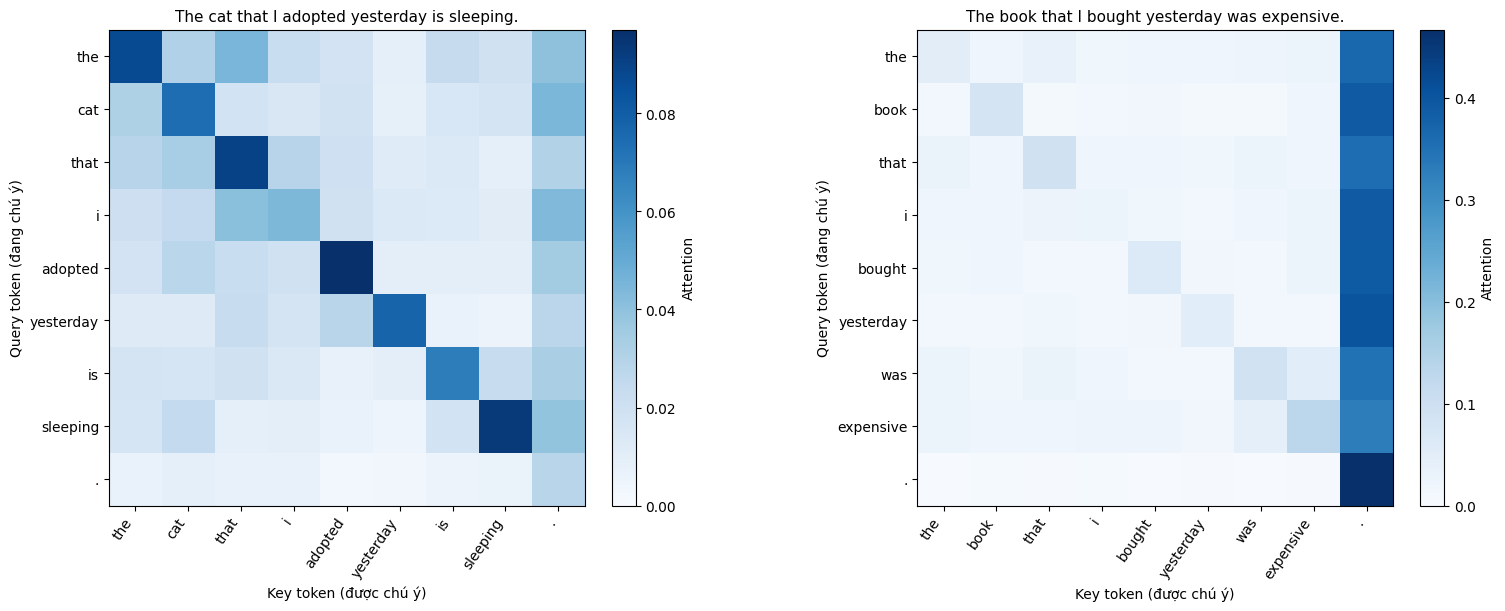

cat attends most to: . (0.044), the (0.031), adopted (0.018), that (0.018), sleeping (0.017)
adopted attends most to: . (0.035), cat (0.028), that (0.023), i (0.019), the (0.018)
sleeping attends most to: . (0.039), cat (0.025), is (0.018), the (0.016), i (0.009)


In [ ]:
# Bài 23 - Attention visualization
# Heatmap chỉ cho thấy phân phối attention, không chứng minh mô hình hiểu ngữ pháp.
%pip -q install transformers

import re
import numpy as np
import torch
import matplotlib.pyplot as plt
from transformers import AutoModel, AutoTokenizer

MODEL_NAME = "bert-base-uncased"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModel.from_pretrained(
    MODEL_NAME,
    output_attentions=True,
    attn_implementation="eager",
).to(device)
model.eval()

sentences = [
    "The cat that I adopted yesterday is sleeping.",
    "The book that I bought yesterday was expensive.",
]

def get_attention(sentence):
    encoded = tokenizer(
        sentence, return_tensors="pt", return_offsets_mapping=True
    )
    offsets = encoded.pop("offset_mapping")[0].tolist()
    encoded = {name: tensor.to(device) for name, tensor in encoded.items()}

    with torch.inference_mode():
        outputs = model(**encoded)

    # Trung bình attention của các head ở layer cuối.
    attention = outputs.attentions[-1][0].mean(dim=0).cpu().numpy()
    token_ids = encoded["input_ids"][0].cpu().tolist()
    tokens = tokenizer.convert_ids_to_tokens(token_ids)
    visible = [
        i for i, token in enumerate(tokens)
        if token not in {tokenizer.cls_token, tokenizer.sep_token, tokenizer.pad_token}
    ]
    return tokens, offsets, attention, visible

results = [get_attention(sentence) for sentence in sentences]

# Vẽ attention matrix cho cả hai câu; trục y là query, trục x là key.
fig, axes = plt.subplots(1, 2, figsize=(16, 6), constrained_layout=True)
for ax, sentence, result in zip(axes, sentences, results):
    tokens, _, attention, visible = result
    matrix = attention[np.ix_(visible, visible)]
    labels = [tokens[i] for i in visible]
    image = ax.imshow(matrix, cmap="Blues", vmin=0, vmax=matrix.max())
    ax.set_title(sentence, fontsize=11)
    ax.set_xticks(range(len(labels)), labels=labels, rotation=55, ha="right")
    ax.set_yticks(range(len(labels)), labels=labels)
    ax.set_xlabel("Key token (được chú ý)")
    ax.set_ylabel("Query token (đang chú ý)")
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04, label="Attention")
plt.show()

# Xem 5 token có attention cao nhất từ cat, adopted, sleeping.
def indices_for_word(word, sentence, offsets):
    match = re.search(re.escape(word), sentence, flags=re.IGNORECASE)
    if match is None:
        raise ValueError(f"Không tìm thấy '{word}' trong câu.")
    start, end = match.span()
    return [
        i for i, (token_start, token_end) in enumerate(offsets)
        if token_end > token_start and token_start < end and token_end > start
    ]

sentence = sentences[0]
tokens, offsets, attention, visible = results[0]
for word in ["cat", "adopted", "sleeping"]:
    query_indices = indices_for_word(word, sentence, offsets)
    scores = attention[query_indices].mean(axis=0)
    candidates = [i for i in visible if i not in query_indices]
    top_indices = sorted(candidates, key=lambda i: scores[i], reverse=True)[:5]
    print(f"{word} attends most to: " + ", ".join(
        f"{tokens[i]} ({scores[i]:.3f})" for i in top_indices
    ))